# Forecasting the Transition from Fossil Fuels to Renewable Energy

## 1. Import required libraries

This section imports the libraries used for file handling, data preparation, Ridge regression, validation metrics, and visualization.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Load and prepare the merged dataset

This section loads `CSV/merged.csv`, extracts energy-mix records, and combines them with yearly CO2 records using year and ISO3 country code.

In [7]:
notebook_dir = Path.cwd()
if (notebook_dir / "sample_data" / "merged.csv").exists():
    csv_path = notebook_dir / "sample_data" / "merged.csv"
elif (notebook_dir / "CSV" / "merged.csv").exists():
    csv_path = notebook_dir / "CSV" / "merged.csv"
else:
    csv_path = notebook_dir / "Data-Mining" / "CSV" / "merged.csv"

merged = pd.read_csv(csv_path, low_memory=False)
energy_columns = ["year", "country", "iso3", "region", "coal_pct", "oil_pct", "gas_pct", "nuclear_pct", "hydro_pct", "solar_pct", "wind_pct", "other_renewables_pct", "renewables_total_pct", "fossil_total_pct"]
energy = merged.loc[merged["source_file"].eq("energy_mix_yearly.csv"), energy_columns].copy()
co2_columns = ["year", "iso3", "co2_emissions_mt", "population_millions", "co2_per_capita_t", "co2_intensity_kg_per_gdp_usd"]
co2 = merged.loc[merged["source_file"].eq("co2_emissions_yearly.csv"), co2_columns].copy()
energy = energy.merge(co2, on=["year", "iso3"], how="left").sort_values(["country", "year"]).reset_index(drop=True)
print(f"Country-energy rows: {len(energy):,}; years: {energy.year.min()}-{energy.year.max()}; countries: {energy.country.nunique()}")

Country-energy rows: 1,350; years: 2000-2026; countries: 50


## 3. Create time-series lag features

This section creates one-year and two-year lag features for renewable, fossil, and individual fuel shares so the model can learn from previous energy-mix patterns.

In [8]:
lag_columns = ["renewables_total_pct", "fossil_total_pct", "coal_pct", "oil_pct", "gas_pct", "nuclear_pct", "hydro_pct", "solar_pct", "wind_pct"]
model_data = energy.copy()
for column in lag_columns:
    model_data[f"{column}_lag1"] = model_data.groupby("country", observed=True)[column].shift(1)
    model_data[f"{column}_lag2"] = model_data.groupby("country", observed=True)[column].shift(2)
feature_columns = ["year", "co2_emissions_mt", "population_millions", "co2_per_capita_t", "co2_intensity_kg_per_gdp_usd"]
feature_columns += [f"{column}_lag{i}" for i in (1, 2) for column in lag_columns]
model_data = model_data.dropna(subset=feature_columns + ["renewables_total_pct", "fossil_total_pct"])
print(f"Training-ready observations: {len(model_data):,}")

Training-ready observations: 1,250


## 4. Train and validate the prediction model

This section trains Ridge regression models with country encoding and standardized numeric features. Data through 2023 is used for training, while 2024–2026 is held out for MAE, RMSE, and R² validation.

In [9]:
train = model_data[model_data.year <= 2023].copy()
test = model_data[(model_data.year >= 2024) & (model_data.year <= 2026)].copy()
targets = ["renewables_total_pct", "fossil_total_pct"]
models = {}
test_predictions = test[["country", "year"] + targets].copy()
preprocessor = ColumnTransformer([
    ("country", OneHotEncoder(handle_unknown="ignore"), ["country"]),
    ("numeric", StandardScaler(), feature_columns),
])
for target in targets:
    model = Pipeline([("preprocessor", preprocessor), ("regressor", Ridge(alpha=10.0))])
    model.fit(train[["country"] + feature_columns], train[target])
    test_predictions[f"predicted_{target}"] = np.clip(model.predict(test[["country"] + feature_columns]), 0, 100)
    models[target] = model
    actual = test_predictions[target]
    predicted = test_predictions[f"predicted_{target}"]
    print(f"{target}: MAE={mean_absolute_error(actual, predicted):.3f}; RMSE={mean_squared_error(actual, predicted) ** 0.5:.3f}; R2={r2_score(actual, predicted):.3f}")

renewables_total_pct: MAE=1.566; RMSE=1.985; R2=0.973
fossil_total_pct: MAE=1.636; RMSE=2.061; R2=0.976


## 5. Forecast 2027–2035 recursively

This section predicts renewable and fossil shares for each country year by year. Predicted values become lag inputs for the next year, and the forecast is saved as `renewable_fossil_forecast_2027_2035.csv`.

In [11]:
forecast_rows = []
for country, country_history in energy.groupby("country", observed=True):
    country_history = country_history.sort_values("year")
    latest = country_history.iloc[-1].copy()
    for year in range(2027, 2036):
        lag1 = country_history.iloc[-1]
        lag2 = country_history.iloc[-2] if len(country_history) >= 2 else lag1
        row = {"country": country, "year": year}
        for column in ["co2_emissions_mt", "population_millions", "co2_per_capita_t", "co2_intensity_kg_per_gdp_usd"]:
            row[column] = latest[column] if pd.notna(latest[column]) else 0
        for lag_number, lag_row in ((1, lag1), (2, lag2)):
            for column in lag_columns:
                row[f"{column}_lag{lag_number}"] = lag_row[column]
        prediction = {}
        for target in targets:
            prediction[target] = float(np.clip(models[target].predict(pd.DataFrame([row]))[0], 0, 100))
        forecast_rows.append({"country": country, "year": year, **prediction})
        new_row = latest.copy()
        new_row["year"] = year
        for target in targets:
            new_row[target] = prediction[target]
        country_history = pd.concat([country_history, pd.DataFrame([new_row])], ignore_index=True)

forecast = pd.DataFrame(forecast_rows)
forecast["renewable_minus_fossil_pct"] = forecast["renewables_total_pct"] - forecast["fossil_total_pct"]
forecast_path = notebook_dir / "CSV" / "renewable_fossil_forecast_2027_2035.csv"
# Automatically create the directory if it doesn't exist
forecast_path.parent.mkdir(parents=True, exist_ok=True)
forecast.to_csv(forecast_path, index=False)
print(f"Saved forecast: {forecast_path}")
forecast.groupby("year")[["renewables_total_pct", "fossil_total_pct"]].mean().round(2)

Saved forecast: /content/CSV/renewable_fossil_forecast_2027_2035.csv


,renewables_total_pct,fossil_total_pct
year,,
2027,23.44,71.45
2028,23.69,71.20
2029,23.99,70.91
2030,24.24,70.66
2031,24.49,70.42
2032,24.72,70.20
2033,24.94,69.98
2034,25.16,69.77
2035,25.37,69.56


## 6. Visualize the historical and forecasted energy mix

This section calculates country averages for renewable and fossil shares, compares historical values with the 2027–2035 forecast, and plots the transition over time.

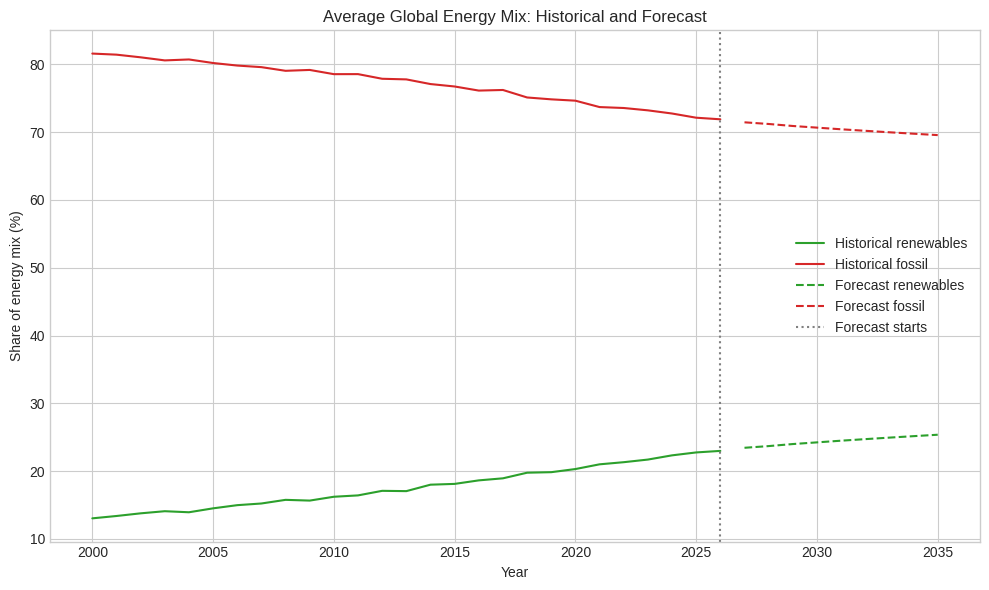

In [12]:
historical_average = energy.groupby("year")[["renewables_total_pct", "fossil_total_pct"]].mean().reset_index()
forecast_average = forecast.groupby("year")[["renewables_total_pct", "fossil_total_pct"]].mean().reset_index()
plt.figure(figsize=(10, 6))
plt.plot(historical_average.year, historical_average.renewables_total_pct, label="Historical renewables", color="#2ca02c")
plt.plot(historical_average.year, historical_average.fossil_total_pct, label="Historical fossil", color="#d62728")
plt.plot(forecast_average.year, forecast_average.renewables_total_pct, "--", label="Forecast renewables", color="#2ca02c")
plt.plot(forecast_average.year, forecast_average.fossil_total_pct, "--", label="Forecast fossil", color="#d62728")
plt.axvline(2026, color="gray", linestyle=":", label="Forecast starts")
plt.title("Average Global Energy Mix: Historical and Forecast")
plt.xlabel("Year")
plt.ylabel("Share of energy mix (%)")
plt.legend()
plt.tight_layout()
plt.show()

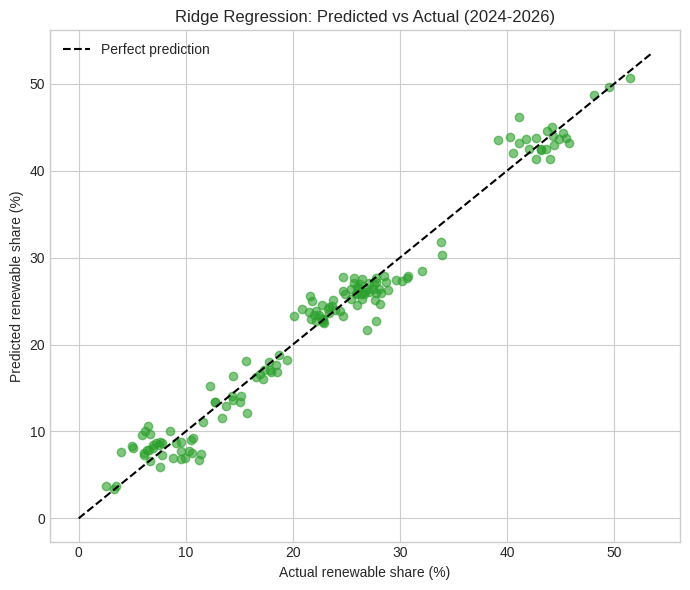

In [13]:
actual = test_predictions["renewables_total_pct"]
predicted = test_predictions["predicted_renewables_total_pct"]

plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.6, color="#2ca02c")
limits = [0, max(actual.max(), predicted.max()) + 2]
plt.plot(limits, limits, "k--", label="Perfect prediction")
plt.xlabel("Actual renewable share (%)")
plt.ylabel("Predicted renewable share (%)")
plt.title("Ridge Regression: Predicted vs Actual (2024-2026)")
plt.legend()
plt.tight_layout()
plt.savefig("figure1_predicted_vs_actual.png", dpi=200)
plt.show()

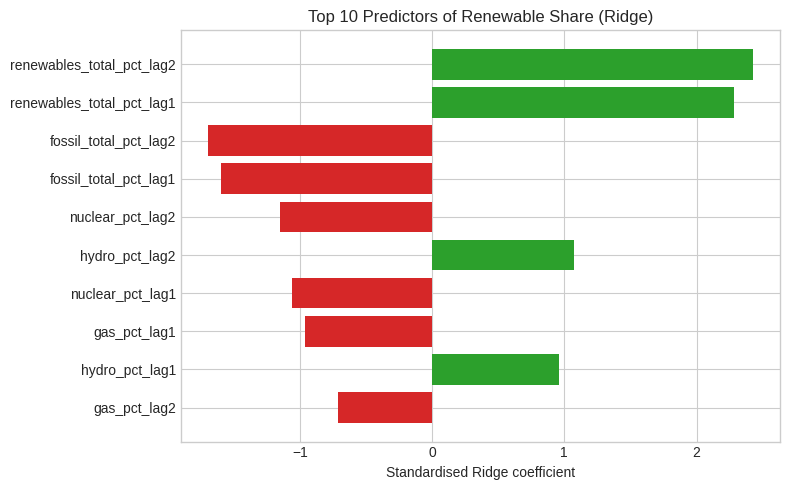

           abs_error  error
country                    
Qatar           3.30  -0.84
Australia       3.10  -3.10
Indonesia       2.88  -0.67
Morocco         2.83   0.53
Egypt           2.70   0.01
Iraq            2.62   0.11
Algeria         2.60   0.95
Malaysia        2.58  -0.81
MAE all features: 1.566
MAE lag features only: 1.508
MAE without lag features: 3.753


In [14]:
model = models["renewables_total_pct"]
names = list(model.named_steps["preprocessor"].named_transformers_["country"]
             .get_feature_names_out(["country"])) + feature_columns
coefs = pd.Series(model.named_steps["regressor"].coef_, index=names)[feature_columns]
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color=["#2ca02c" if v > 0 else "#d62728" for v in top.values])
plt.xlabel("Standardised Ridge coefficient")
plt.title("Top 10 Predictors of Renewable Share (Ridge)")
plt.tight_layout()
plt.savefig("figure3_top_predictors.png", dpi=200)
plt.show()

errors = test_predictions.copy()
errors["error"] = errors["predicted_renewables_total_pct"] - errors["renewables_total_pct"]
errors["abs_error"] = errors["error"].abs()
print(errors.groupby("country")[["abs_error", "error"]].mean()
      .sort_values("abs_error", ascending=False).head(8).round(2))

def test_mae(cols):
    pipe = Pipeline([("pre", ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), ["country"]),
                                                ("n", StandardScaler(), cols)])),
                     ("reg", Ridge(alpha=10.0))])
    pipe.fit(train[["country"] + cols], train["renewables_total_pct"])
    pred = np.clip(pipe.predict(test[["country"] + cols]), 0, 100)
    return mean_absolute_error(test["renewables_total_pct"], pred)

lag_only = [c for c in feature_columns if "lag" in c]
no_lag = [c for c in feature_columns if "lag" not in c]
print("MAE all features:", round(test_mae(feature_columns), 3))
print("MAE lag features only:", round(test_mae(lag_only), 3))
print("MAE without lag features:", round(test_mae(no_lag), 3))